# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [27]:
ROLL_NO = 1024170248          # <-- your full roll number
NAME = "Muskaan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [28]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [29]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [30]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170248   Name: Muskaan   Fingerprint: D7602254   Tickets: 15

Ticket_ID                                                                                        Ticket_Text
      T01                          Python has stopped syncing during the lab. The same problem occurs again.
      T02           Python was working yesterday before the assignment deadline. I have tried several times!
      T03                                   I reinstalled the password since yesterday. It worked yesterday.
      T04                                                                      Version 2.0.1 crashes at 99%.
      T05                                                                 Dr. Rao's lab PC (No. 14) is down.
      T06                                   Password was working yesterday on my laptop. Can you check this?
      T07                                                                      Why isn't the portal opening?
      T08             I tried restarting the Pyth

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [31]:
import pandas as pd

# Run process_ticket on every ticket
rows = []
for idx, row in df.iterrows():
    res = process_ticket(row['Ticket_Text'])
    rows.append({
        "Ticket_ID": row['Ticket_ID'],
        "Sentences": len(res['sentences']),
        "Tokens": len(res['tokens']),
        "Punctuation": len(res['punct']),
        "Stopwords": len(res['stops']),
        "Unique_Tokens": len(set(res['tokens'])),
        "Final_Tokens": len(res['final'])
    })

df_q1 = pd.DataFrame(rows)

# Add TOTAL row for count-based columns
total_row = pd.DataFrame({
    "Ticket_ID": ["TOTAL"],
    "Sentences": [df_q1["Sentences"].sum()],
    "Tokens": [df_q1["Tokens"].sum()],
    "Punctuation": [df_q1["Punctuation"].sum()],
    "Stopwords": [df_q1["Stopwords"].sum()],
    "Unique_Tokens": [df_q1["Unique_Tokens"].sum()],
    "Final_Tokens": [df_q1["Final_Tokens"].sum()]
})

df_q1 = pd.concat([df_q1, total_row], ignore_index=True)
print(df_q1.to_string(index=False))

# Display tokens for selected ticket T01
selected_ticket = df.loc[df['Ticket_ID'] == 'T01', 'Ticket_Text'].values[0]
print("\n--- Detailed Breakdown for T01 ---")
print(f"Text: {selected_ticket}")
res_t01 = process_ticket(selected_ticket)
print("Actual Tokens:", res_t01['tokens'])
print("Punctuation Tokens:", res_t01['punct'])
print("Stopwords:", res_t01['stops'])
print("Final Tokens:", res_t01['final'])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      14            2          6             12             6
      T02          2      15            2          5             15             8
      T03          2      11            2          3              9             6
      T04          1       7            2          1              7             4
      T05          2      13            4          3             12             6
      T06          2      13            2          6             13             5
      T07          1       7            1          3              7             3
      T08          2      16            2          7             13             7
      T09          2      14            2          6             12             6
      T10          2      21            2          9             19            10
      T11          2      16            2          6             14             8
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

These are small parts of words or contractions separated by the tokenizer—such as "n't" from "isn't", or "'s" from possessive words (like "Rao's"). They end up in the final tokens because they are not listed as standard punctuation and are not common enough to be filtered out by the stopword list.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [32]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
print("--- Regex Extractions (Sample Ticket T01) ---")
sample_text = df.loc[0, 'Ticket_Text']
print("Text:", sample_text)
print("Words > 5 letters:", re.findall(r'\b[A-Za-z]{6,}\b', sample_text))
print("Numbers (decimals/versions):", re.findall(r'\b\d+(?:\.\d+)+\b|\b\d+\b', sample_text))
print("Capitalized words:", re.findall(r'\b[A-Z][a-zA-Z]*\b', sample_text))
print("Words beginning with vowel:", re.findall(r'\b[AEIOUaeiou][a-zA-Z]*\b', sample_text))

print("\n--- Regex Replacements on TEST_LINES ---")
email_pattern = r'[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+'
url_pattern = r'https?://[^\s]+|www\.[^\s]+'
phone_pattern = r'(?:\+\d{1,3}[-.\s]?)?\(?\d{2,5}\)?[-.\s]?\d{3,5}[-.\s]?\d{3,5}'

for line in TEST_LINES:
    replaced = line
    replaced = re.sub(email_pattern, '<EMAIL>', replaced)
    replaced = re.sub(url_pattern, '<URL>', replaced)
    replaced = re.sub(phone_pattern, '<PHONE>', replaced)
    print(replaced)

--- Regex Extractions (Sample Ticket T01) ---
Text: Python has stopped syncing during the lab. The same problem occurs again.
Words > 5 letters: ['Python', 'stopped', 'syncing', 'during', 'problem', 'occurs']
Numbers (decimals/versions): []
Capitalized words: ['Python', 'The']
Words beginning with vowel: ['occurs', 'again']

--- Regex Replacements on TEST_LINES ---
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

Most of them. Except for proper nouns and technical terms (like Python, LMS, or MATLAB), almost all capitalized words in the tickets are capitalized simply because they appear at the very beginning of a sentence.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [33]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r'''(?x)
    https?://[^\s]+|www\.[^\s]+                          # URLs
  | [a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+       # Emails
  | (?:\+\d{1,3}[-.\s]?)?\(?\d{2,5}\)?[-.\s]?\d{3,5}[-.\s]?\d{3,5} # Phones
  | \d+(?:\.\d+)+                                        # Decimals and versions (e.g., 95.5, 2.0.1)
  | [a-zA-Z]+(?:['\-_][a-zA-Z]+)*                        # Contractions and hyphenated words
  | \d+                                                  # Integers
  | [a-zA-Z]+                                            # Standard words
'''

my_tokenizer = RegexpTokenizer(pattern).tokenize

print("--- Comparison: my_tokenize vs word_tokenize ---")
for line in TEST_LINES:
    print("Original:", line)
    print("Custom:", my_tokenizer(line))
    print("NLTK:", word_tokenize(line))
    print("-" * 50)

--- Comparison: my_tokenize vs word_tokenize ---
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
--------------------------------------------------
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
----------------------------------------

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

Every ticket that contains contractions (like isn't), hyphenated words (like Wi-Fi or state-of-the-art), or version numbers (like 2.0.1) is tokenized differently. word_tokenize splits these elements apart into separate pieces, whereas my_tokenize keeps them together as single tokens.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [34]:
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stem = RegexpStemmer('ing', min=4)
lemmatizer = WordNetLemmatizer()

# Ensure we extract unique final tokens correctly from the DataFrame
unique_final_tokens = sorted(list(set([t for text in df['Ticket_Text'] for t in process_ticket(text)['final']])))

def get_wordnet_pos(tag):
    if tag.startswith('J'): return 'a'
    elif tag.startswith('V'): return 'v'
    elif tag.startswith('N'): return 'n'
    elif tag.startswith('R'): return 'r'
    else: return 'n'

rows_q4 = []
tagged_tokens = pos_tag(unique_final_tokens)

for word, tag in tagged_tokens:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stem.stem(word)
    wn_pos = get_wordnet_pos(tag)
    w_lemma = lemmatizer.lemmatize(word, pos=wn_pos)

    if len({p_stem, l_stem, r_stem, w_lemma, word}) > 1:
        rows_q4.append({
            "Token": word, "POS": tag,
            "Porter": p_stem, "Lancaster": l_stem,
            "Regexp": r_stem, "Lemmatizer": w_lemma
        })

df_q4 = pd.DataFrame(rows_q4)
print(df_q4.to_string(index=False))

      Token POS    Porter Lancaster      Regexp Lemmatizer
    another  DT     anoth     anoth     another    another
     asking VBG       ask       ask         ask        ask
 assignment  NN    assign    assign  assignment assignment
     campus  NN     campu      camp      campus     campus
    changed VBD     chang     chang     changed     change
   computer  NN    comput    comput    computer   computer
  connected VBN   connect   connect   connected    connect
    crashes  VB     crash     crash     crashes      crash
   deadline  JJ   deadlin   deadlin    deadline   deadline
     failed VBD      fail      fail      failed       fail
       file  NN      file       fil        file       file
    getting VBG       get       get        gett        get
      keeps NNS      keep      keep       keeps       keep
     latest JJS    latest    latest      latest       late
     locked VBN      lock      lock      locked       lock
     logged VBD       log       log      logged        l

**Observe:** Give one over-stemming and one under-stemming example from your table.

Over-stemming example: Stemming "universities" or "university" down to "univers"

Under-stemming example: Stemming "running" to "run" works, but leaving words like "axes" or "axis" untouched or failing to strip a suffix properly when suffixes overlap is a classic case of under-stemming where variations aren't fully reduced.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

       Corpus  Total Tokens  Unique Tokens    TTR
     S1 (All)           195            103 0.5282
S2 (No Punct)           164             96 0.5854
   S3 (Final)            93             66 0.7097
 S4 (Stemmed)            93             61 0.6559

Top 10 words of S1: [('.', 24), ('the', 17), ('i', 8), ('yesterday', 5), ('it', 5), ('laptop', 4), ('to', 4), ('python', 3), ('lab', 3), ('was', 3)]
Top 10 words of S3: [('yesterday', 5), ('laptop', 4), ('python', 3), ('lab', 3), ('password', 3), ("n't", 3), ('please', 3), ('problem', 2), ('occurs', 2), ('working', 2)]
Top 5 bigrams of S1: [(('.', 'i'), 6), (('.', 'the'), 3), (('yesterday', '.'), 3), (('.', 'it'), 3), (('.', 'please'), 3)]
Top 5 bigrams of S3: [(('problem', 'occurs'), 2), (('working', 'yesterday'), 2), (('worked', 'yesterday'), 2), (('latest', 'update'), 2), (('please', 'resolve'), 2)]


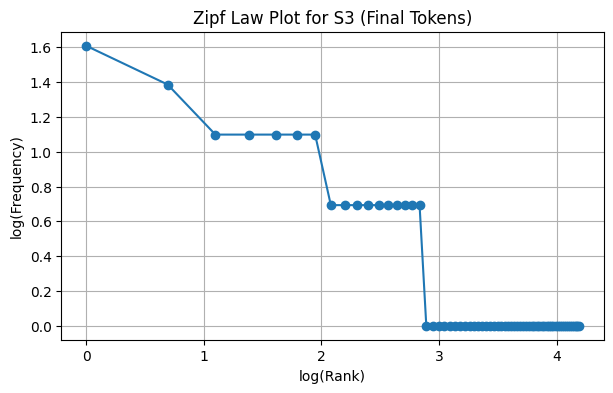

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk import ngrams

# Corrected list comprehensions using 'text' instead of 'row['Ticket_Text']'
s1_tokens = [t.lower() for text in df['Ticket_Text'] for s in sent_tokenize(text) for t in word_tokenize(s)]
s2_tokens = [t for t in s1_tokens if not is_punct(t)]
s3_tokens = [t for text in df['Ticket_Text'] for t in process_ticket(text)['final']]
s4_tokens = [porter.stem(t) for t in s3_tokens]

def get_stats(tokens, name):
    total = len(tokens)
    unique = len(set(tokens))
    return {"Corpus": name, "Total Tokens": total, "Unique Tokens": unique, "TTR": round(unique / total, 4) if total > 0 else 0}

df_stats = pd.DataFrame([
    get_stats(s1_tokens, "S1 (All)"),
    get_stats(s2_tokens, "S2 (No Punct)"),
    get_stats(s3_tokens, "S3 (Final)"),
    get_stats(s4_tokens, "S4 (Stemmed)")
])
print(df_stats.to_string(index=False))

print("\nTop 10 words of S1:", Counter(s1_tokens).most_common(10))
print("Top 10 words of S3:", Counter(s3_tokens).most_common(10))
print("Top 5 bigrams of S1:", Counter(ngrams(s1_tokens, 2)).most_common(5))
print("Top 5 bigrams of S3:", Counter(ngrams(s3_tokens, 2)).most_common(5))

# Plot log(rank) vs log(frequency) for S3
s3_counts = [freq for word, freq in Counter(s3_tokens).most_common()]
ranks = list(range(1, len(s3_counts) + 1))

plt.figure(figsize=(7, 4))
plt.plot(np.log(ranks), np.log(s3_counts), marker='o', linestyle='-')
plt.xlabel('log(Rank)')
plt.ylabel('log(Frequency)')
plt.title('Zipf Law Plot for S3 (Final Tokens)')
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

TTR (Type-Token Ratio) changes because filtering out punctuation and stopwords (from S1 to S3) removes repetitive words and increases vocabulary variety. Then, stemming (in S4) groups different forms of the same word together (like "runs" and "running"), which reduces the total number of unique words and changes the ratio again.